COMPROBACION: K=2, N=101, m=5, s=2, T=6000 contra Fase8_binario_validacion


  sigma2/N promedio: ahora 0.1041619494  validacion 0.1041619494
  sigma2/N por cadena, np.array_equal = True



Referencia de agentes al azar:


  K=2  M(1)=1.208e-05  C(6)=7.710e-04  [35.4 s]


  K=3  M(1)=5.252e-05  C(6)=8.827e-03  [35.2 s]



Juego binario:


... (18 outputs left out)

s=3 m= 9  gamma=  5.06931  frec(0,1)=(0.500, 0.500)  M(1)=2.555e-04  M_max=3.874e-04 (d=5)  C(6)=1.713e-02  c(6)=2.855e-03  [53.1 s]


s=3 m=10  gamma= 10.13861  frec(0,1)=(0.501, 0.499)  M(1)=1.710e-04  M_max=2.161e-04 (d=5)  C(6)=1.095e-02  c(6)=1.824e-03  [54.5 s]



Graficas de s = 2:


  Guardado: graficas\Fase8_binario_Md_con_puntaje_N101_s2_T60000_promedio.png


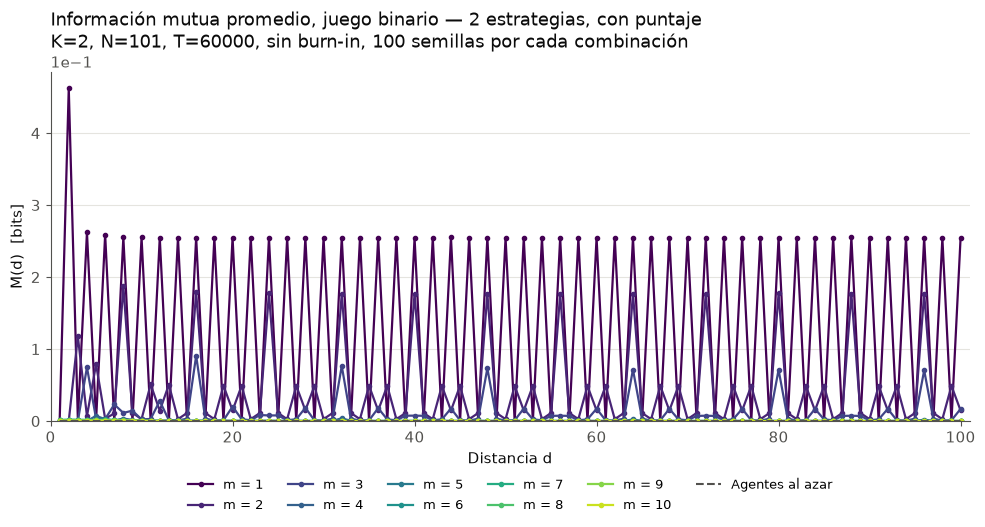

  Guardado: graficas\Fase8_binario_CK_con_puntaje_N101_s2_T60000_promedio.png


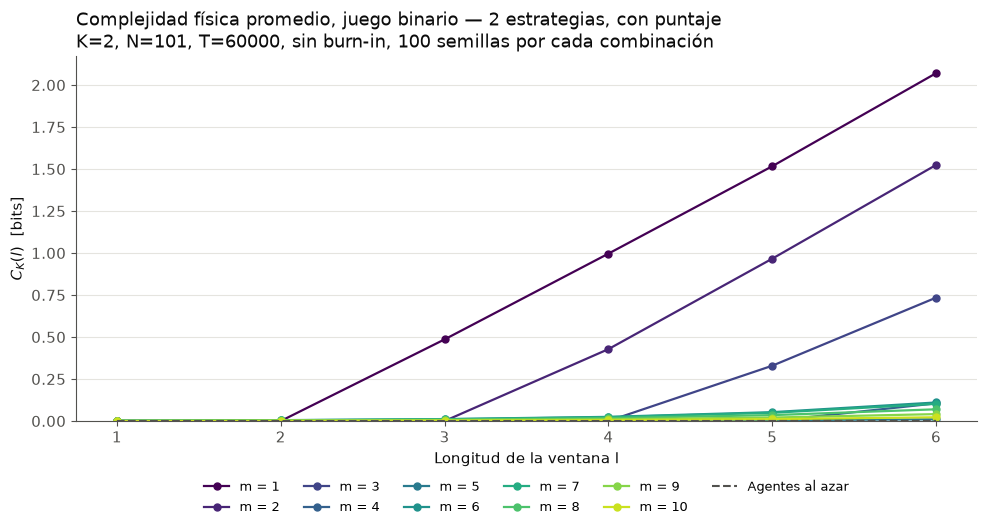

  Guardado: graficas\Fase8_comparacion_c6_contra_m_con_puntaje_N101_s2_T60000.png


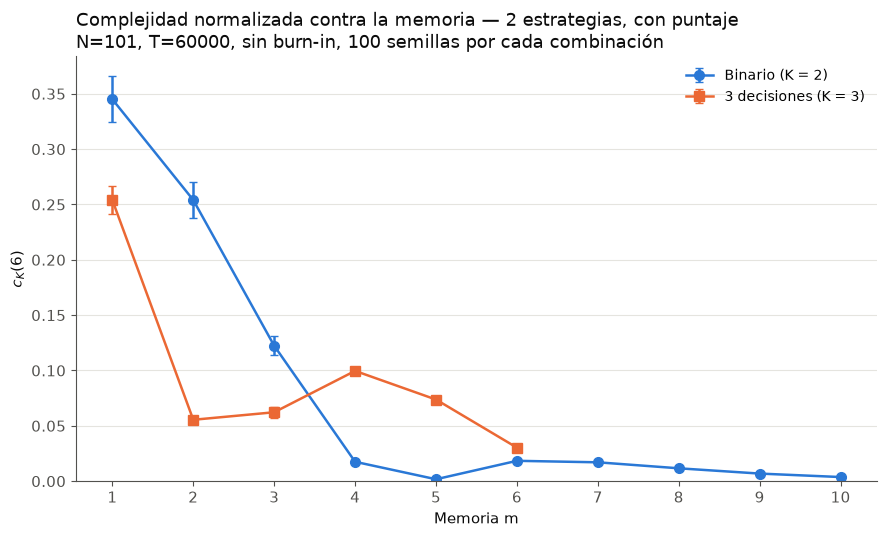

  Guardado: graficas\Fase8_comparacion_c6_contra_gamma_con_puntaje_N101_s2_T60000.png


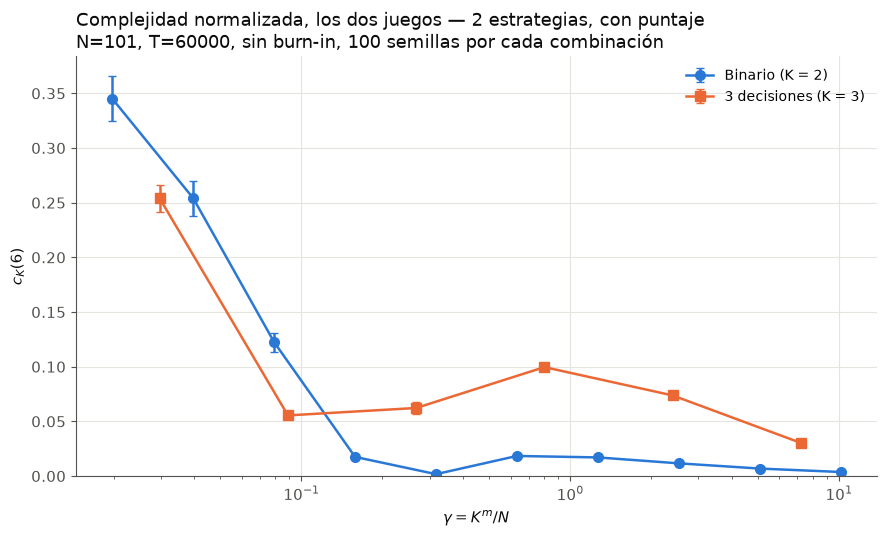

  Guardado: graficas\Fase8_comparacion_M1_con_puntaje_N101_s2_T60000.png


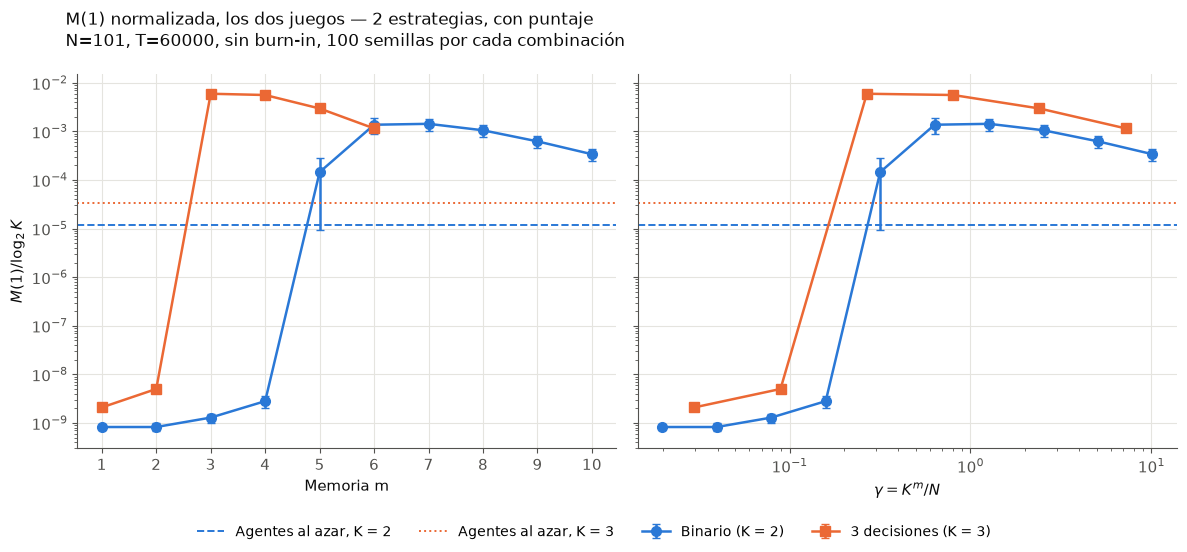


Graficas de s = 3:


  Guardado: graficas\Fase8_binario_Md_con_puntaje_N101_s3_T60000_promedio.png


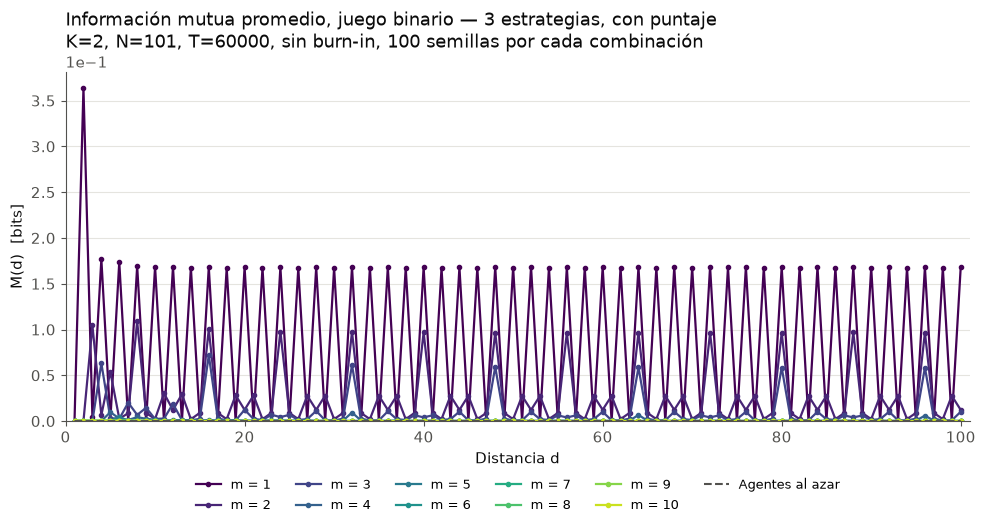

  Guardado: graficas\Fase8_binario_CK_con_puntaje_N101_s3_T60000_promedio.png


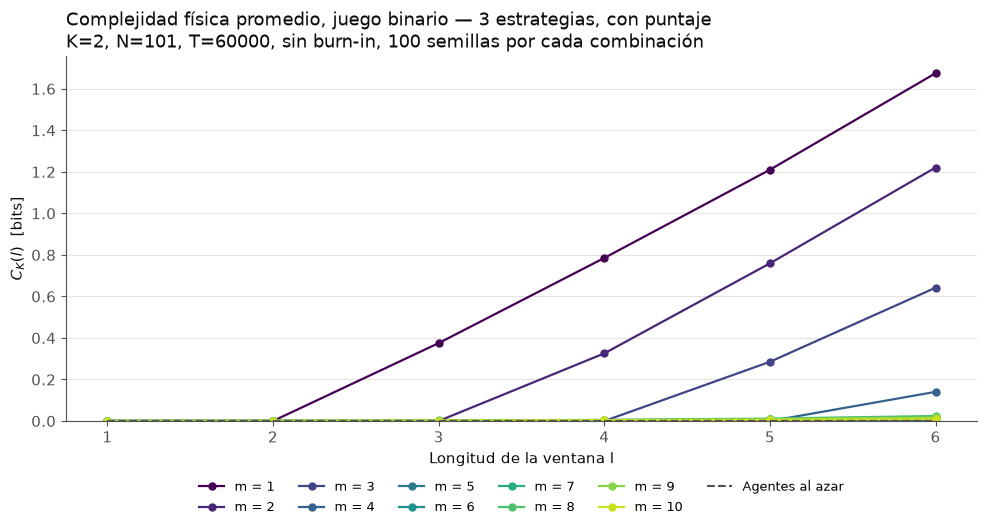

  Guardado: graficas\Fase8_comparacion_c6_contra_m_con_puntaje_N101_s3_T60000.png


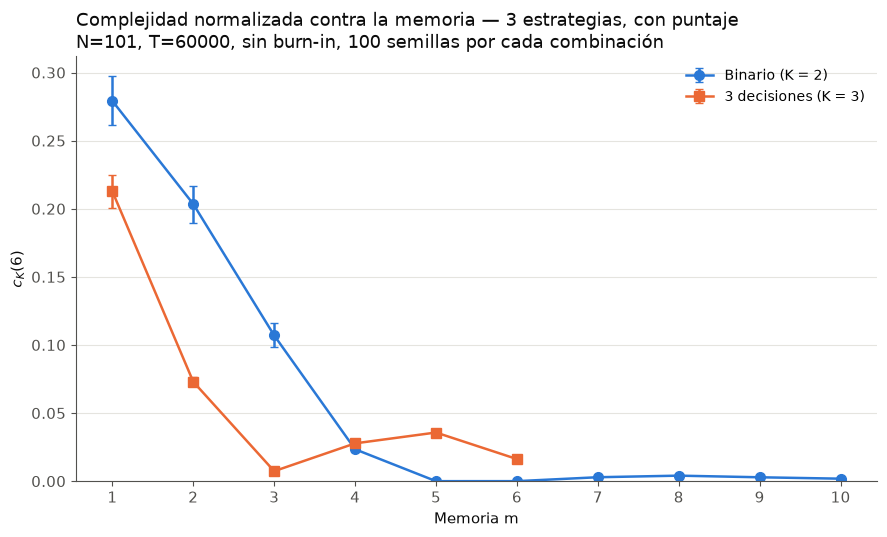

  Guardado: graficas\Fase8_comparacion_c6_contra_gamma_con_puntaje_N101_s3_T60000.png


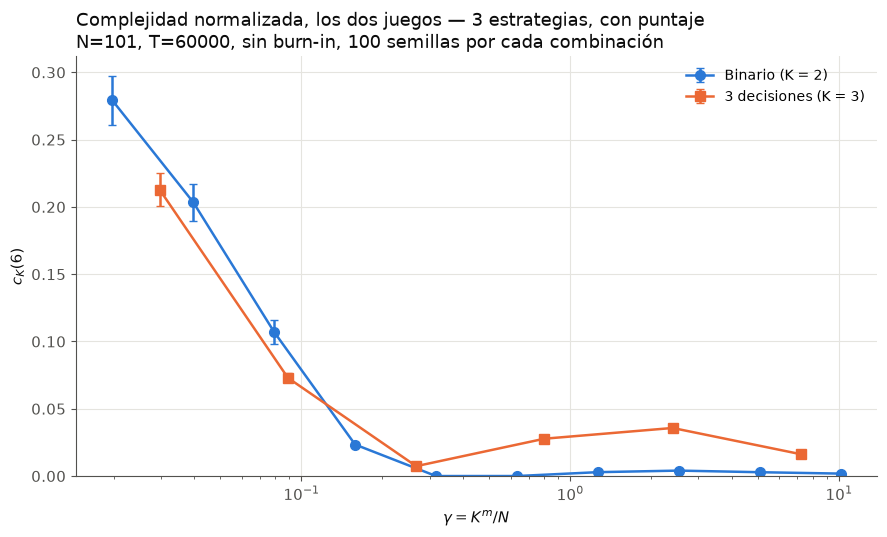

  Guardado: graficas\Fase8_comparacion_M1_con_puntaje_N101_s3_T60000.png


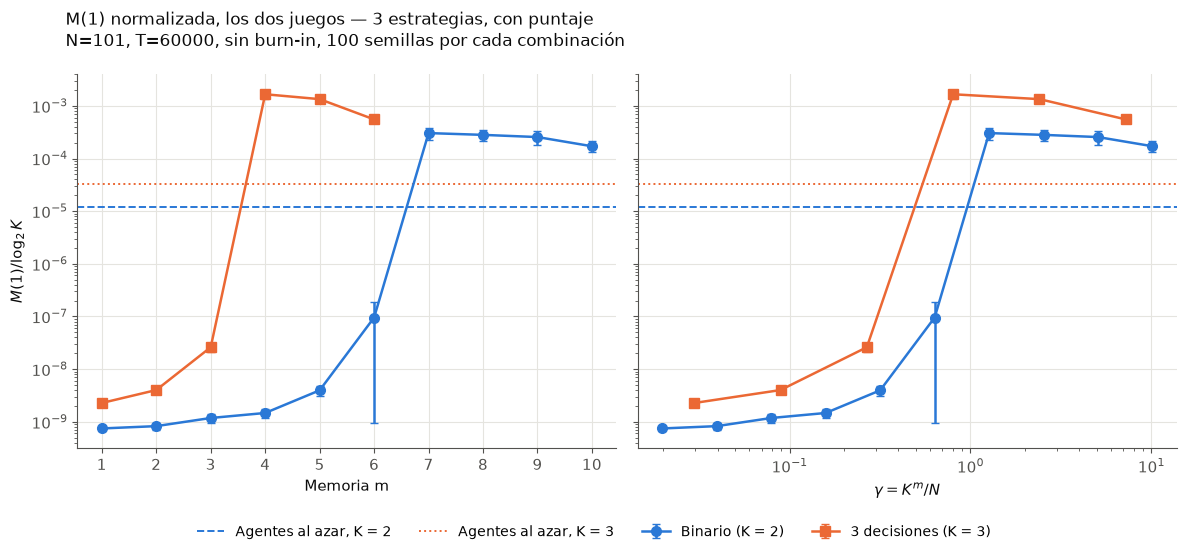


Guardado: csv\Fase8_resumen_binario_y_3decisiones_con_puntaje_N101_T60000.csv

Listo. Tiempo total: 18.6 min


In [1]:
"""
FASE 8, PASO 2 - Juego binario: variacion de la memoria m con N fijo
====================================================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion
Base: R. Mansilla, Phys. Rev. E 62, 4553 (2000), Ec. (6)

Alfabeto: {0, 1}. Mismos N, T, d, l y semillas que la Fase 7, para que el juego
binario y el de 3 decisiones sean comparables.

Que hace este codigo:
  1. Comprueba que el caso K=2, N=101, m=5, s=2, T=6000 da exactamente lo mismo
     que en Fase8_binario_validacion. Si no, el notebook se detiene.
  2. Para cada combinacion de m y s corre 100 partidas y calcula, por cadena,
     M(d), C_K(l), c_K(l) y M(d)/log2(K). Luego promedia sobre las cadenas.
  3. Calcula la referencia de agentes que eligen al azar, para cada alfabeto.
  4. Dibuja las graficas del binario y las de comparacion con la Fase 7, cuyos
     CSV solo se leen.

gamma = K^m / N es el parametro de control. Va en los CSV, no en los titulos.

Las funciones validar_parametros, regla_ganador, simular_con_puntaje,
informacion_mutua, complejidad_fisica, correr_cadena, correr_N, resumir,
guardar_Md_todas y terminar_figura son las de Fase8_binario_validacion, sin
cambios. simular_ingenuos es la de notebooks/Fase 2, sin cambios.
"""

import os
import time

import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.stats import t as t_student
except ImportError:
    t_student = None
T_95 = 1.984  # t de Student, 95%, 99 g.l. (por si no hay scipy)

try:
    from joblib import Parallel, delayed
    HAY_JOBLIB = True
except ImportError:
    HAY_JOBLIB = False


# =====================================================================
# OPCIONES
# =====================================================================
# Las graficas SIEMPRE se muestran en el notebook.
# True  = ademas se guardan como PNG en CARPETA_GRAFICAS
# False = solo se muestran, no se guarda ningun PNG
DESCARGAR_GRAFICAS = True

# True  = se guardan los CSV en CARPETA_CSV
# False = no se guarda ningun CSV
GUARDAR_CSV        = True

# True = antes de todo, compara el caso m=5 contra Fase8_binario_validacion
HACER_COMPROBACION = True

CARPETA_CSV       = "csv"
CARPETA_GRAFICAS  = "graficas"
CARPETA_CONTEOS   = "conteos"
CARPETA_CSV_FASE7 = os.path.join("..", "Fase 7", "csv")   # solo se lee

#   -1 -> usa TODOS los nucleos
#   -2 -> usa todos menos uno (la computadora queda mas libre mientras corre)
#    1 -> un solo nucleo
N_NUCLEOS = -1


# =====================================================================
# PARAMETROS
# =====================================================================
SEMILLA_MAESTRA = 1907443528   # genera las 100 semillas de forma reproducible
N_CADENAS = 100                # numero de cadenas (semillas distintas)

N       = 101    # numero de agentes
K       = 2      # tamano del alfabeto
T       = 60000  # ciclos registrados, desde el primero (sin burn-in)

LISTA_M = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
LISTA_S = [2, 3]

D_MAX   = 100    # M(d) se calcula para d = 1, ..., D_MAX
L_MAX   = 6      # la complejidad se calcula para l = 1, ..., L_MAX
NIVEL   = 0.95   # nivel de confianza del intervalo

ETIQUETA = "con_puntaje"

# --- Juego de 3 decisiones (Fase 7): solo para leer sus CSV ---
K_FASE7       = 3
LISTA_M_FASE7 = [1, 2, 3, 4, 5, 6]

# --- Referencia de agentes al azar ---
M_AZAR = 3       # los agentes al azar no consultan la memoria

# --- Caso de la comprobacion ---
N_COMP, M_COMP, S_COMP, K_COMP, T_COMP = 101, 5, 2, 2, 6000


# =====================================================================
# NUCLEO VALIDADO  (igual que en Fase8_binario_validacion)
# =====================================================================
def validar_parametros(N, K):
    """Con K = 2, N impar evita el empate entre las dos opciones.
    Con K = 3, N no multiplo de 3 evita el empate entre las tres."""
    if K == 2 and N % 2 == 0:
        raise ValueError(f"Con K = 2, N debe ser impar (N = {N})")
    if K == 3 and N % 3 == 0:
        raise ValueError(f"Con K = 3, N no debe ser multiplo de 3 (N = {N})")


def regla_ganador(conteos, rng):
    """Gana el argmin sobre las K acciones, con desempate aleatorio."""
    empatados = np.flatnonzero(conteos == conteos.min())
    return int(rng.choice(empatados))


def simular_con_puntaje(N, m, s, K, T, semilla):
    """Reglas del codigo base, sin burn-in. Cada agente usa la estrategia
    con mas puntos y, al final del ciclo, todas las estrategias que
    habrian acertado al ganador reciben un punto.

    Devuelve la serie de ganadores, cuantas veces acerto cada agente y
    cuantos agentes eligieron cada opcion en cada turno.
    """
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m

    # estrategias[i, j, h] = accion que la estrategia j del agente i
    #                        recomienda ante la historia con indice h
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))

    # puntajes[i, j] = puntos virtuales (casos de exito) de esa estrategia
    puntajes = np.zeros((N, s))

    # memoria: los m datos que el mercado tiene "al nacer"
    historia = rng.integers(0, K, size=m)

    pesos = K ** np.arange(m - 1, -1, -1)   # convierte historia -> indice
    indices = np.arange(N)

    serie_ganadores = np.zeros(T, dtype=int)
    exitos_agente = np.zeros(N, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)

    for t in range(T):

        # 1. que situacion estan viendo los agentes
        idx = int(historia @ pesos)

        # 2. cada agente toma su estrategia con mas puntos.
        #    El ruido < 1 rompe empates al azar sin alterar el orden
        #    entre puntajes enteros distintos.
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)

        # 3. consulta esa estrategia en la historia actual y actua
        acciones = estrategias[indices, mejor, idx]

        # 4. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 5. gana la minoria
        ganador = regla_ganador(conteos, rng)

        # 6. se premian TODAS las estrategias que hubieran acertado,
        #    se hayan jugado o no (regla del codigo base / PRE 62).
        puntajes += (estrategias[:, :, idx] == ganador)

        # 7. registrar desde el primer ciclo
        serie_ganadores[t] = ganador
        conteos_por_turno[t] = conteos
        exitos_agente += (acciones == ganador)

        # 8. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores, exitos_agente, conteos_por_turno


def informacion_mutua(serie, d, K):
    """M(d) = sum_{a,b} P_ab(d) * log2[ P_ab(d) / (P_a * P_b) ]

    P_ab(d): probabilidad de encontrar el simbolo a y, d lugares despues,
             el simbolo b. Se estima contando todos los pares
             (serie[i], serie[i+d]) de la cadena.
    P_a:     densidad del simbolo a en la cadena completa (como dice
             Mansilla: "the density of the symbol alpha").

    La suma corre sobre los K*K pares (a, b). Los pares que nunca
    aparecen (P_ab = 0) no aportan, porque 0 * log(0) = 0.
    """
    x = serie[:-d]          # simbolo alpha
    y = serie[d:]           # simbolo beta, d lugares despues
    n_pares = len(x)

    # probabilidades conjuntas P_ab(d): matriz K x K
    conjunta = np.bincount(x * K + y, minlength=K * K).reshape(K, K) / n_pares

    # densidades P_a de cada simbolo en toda la cadena
    densidad = np.bincount(serie, minlength=K) / len(serie)
    producto = np.outer(densidad, densidad)      # P_a * P_b

    M_d = 0.0
    for a in range(K):
        for b in range(K):
            if conjunta[a, b] > 0:
                M_d += conjunta[a, b] * np.log2(conjunta[a, b] / producto[a, b])
    return M_d


def complejidad_fisica(serie, l, K):
    """Devuelve C_K(l) y c_K(l) de una cadena de ganadores.

    Una ventana de longitud l recorre la cadena de uno en uno. Cada ventana
    se convierte en un numero (en base K) para contar cuantas veces aparece
    cada subcadena eta. Con esas frecuencias relativas p(eta):

        H(l)   = -sum p(eta) log2 p(eta)
        C_K(l) = l*log2(K) - H(l)
        c_K(l) = C_K(l) / (l*log2(K))
    """
    ventanas = np.lib.stride_tricks.sliding_window_view(serie, l)
    pesos = K ** np.arange(l - 1, -1, -1)
    codigos = ventanas @ pesos
    conteos = np.bincount(codigos, minlength=K ** l)

    p = conteos[conteos > 0] / len(codigos)
    H = -np.sum(p * np.log2(p))

    maximo = l * np.log2(K)
    C = maximo - H
    return C, C / maximo


def correr_cadena(N, m, s, K, T, semilla, d_max, l_max):
    serie, exitos, conteos = simular_con_puntaje(N, m, s, K, T, int(semilla))
    Md = np.array([informacion_mutua(serie, d, K)
                   for d in range(1, d_max + 1)])
    complejidad = np.array([complejidad_fisica(serie, l, K)
                            for l in range(1, l_max + 1)])
    return {
        "Md": Md,
        "C": complejidad[:, 0],
        "c": complejidad[:, 1],
        "frec": np.bincount(serie, minlength=K) / T,
        "tasa_exito": exitos.sum() / (N * T),
        "conteos": conteos,
    }


def correr_N(N, m, s, K, T, semillas, d_max, l_max, n_nucleos):
    """Corre todas las cadenas de un N. El resultado no depende del numero
    de nucleos: cada cadena usa solo su propia semilla y joblib devuelve
    las cadenas en el orden en que se pidieron."""
    validar_parametros(N, K)
    if HAY_JOBLIB and n_nucleos != 1:
        bloque = Parallel(n_jobs=n_nucleos)(
            delayed(correr_cadena)(N, m, s, K, T, int(sem), d_max, l_max)
            for sem in semillas)
    else:
        bloque = [correr_cadena(N, m, s, K, T, int(sem), d_max, l_max)
                  for sem in semillas]
    return {
        "Md": np.array([b["Md"] for b in bloque]),
        "C": np.array([b["C"] for b in bloque]),
        "c": np.array([b["c"] for b in bloque]),
        "frec": np.array([b["frec"] for b in bloque]),
        "tasa_exito": np.array([b["tasa_exito"] for b in bloque]),
        "conteos": np.array([b["conteos"] for b in bloque]),
    }


def resumir(tabla, t_crit):
    """Promedio sobre las cadenas (filas), con su intervalo de confianza."""
    media = tabla.mean(axis=0)
    desv = tabla.std(axis=0, ddof=1)
    error_est = desv / np.sqrt(tabla.shape[0])
    return {"media": media, "desv": desv, "error_est": error_est,
            "ic_inf": media - t_crit * error_est,
            "ic_sup": media + t_crit * error_est}


# =====================================================================
# AGENTES AL AZAR  (simular_ingenuos es la de la Fase 2, K puede ser 2 o 3)
# =====================================================================
def simular_ingenuos(N, m, K, T, burn_in, semilla):
    """Corre una partida con agentes que eligen al azar.

    Cada agente, en cada ciclo, elige 0, 1 o 2 con probabilidad 1/3.
    No hay estrategias, no hay puntajes, no hay aprendizaje.

    La memoria (historia de los ultimos m ganadores) se sigue llevando
    igual que en el codigo base, para que la estructura sea la misma y
    despues solo haya que cambiar la forma de decidir. Pero aqui nadie
    la consulta.
    """
    rng = np.random.default_rng(semilla)

    historia = rng.integers(0, K, size=m)
    serie_ganadores = np.zeros(T, dtype=int)

    for t in range(burn_in + T):

        # 1. cada agente elige al azar entre 0, 1 y 2
        acciones = rng.integers(0, K, size=N)

        # 2. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 3. gana la minoria (misma regla que el codigo base)
        ganador = regla_ganador(conteos, rng)

        # 4. registrar solo despues del transitorio
        if t >= burn_in:
            serie_ganadores[t - burn_in] = ganador

        # 5. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores


def correr_cadena_azar(N, K, T, semilla, d_max, l_max, m_azar):
    serie = simular_ingenuos(N, m_azar, K, T, 0, int(semilla))
    Md = np.array([informacion_mutua(serie, d, K)
                   for d in range(1, d_max + 1)])
    complejidad = np.array([complejidad_fisica(serie, l, K)
                            for l in range(1, l_max + 1)])
    return Md, complejidad[:, 0], complejidad[:, 1]


def correr_referencia(N, K, T, semillas, d_max, l_max, n_nucleos):
    """Agentes al azar con el alfabeto indicado, cadena por cadena."""
    validar_parametros(N, K)
    if HAY_JOBLIB and n_nucleos != 1:
        bloque = Parallel(n_jobs=n_nucleos)(
            delayed(correr_cadena_azar)(N, K, T, int(sem), d_max, l_max, M_AZAR)
            for sem in semillas)
    else:
        bloque = [correr_cadena_azar(N, K, T, int(sem), d_max, l_max, M_AZAR)
                  for sem in semillas]
    return {"Md": np.array([b[0] for b in bloque]),
            "C": np.array([b[1] for b in bloque]),
            "c": np.array([b[2] for b in bloque])}


# =====================================================================
# COMPROBACION CONTRA LA VALIDACION
# =====================================================================
def comprobacion(semillas):
    print(f"COMPROBACION: K={K_COMP}, N={N_COMP}, m={M_COMP}, s={S_COMP}, T={T_COMP} "
          "contra Fase8_binario_validacion", flush=True)
    guardado = np.load(os.path.join(
        CARPETA_CONTEOS,
        f"Fase8_conteos_K{K_COMP}_N{N_COMP}_m{M_COMP}_s{S_COMP}_T{T_COMP}"
        f"_cadenas{len(semillas)}.npz"))["conteos"]
    datos = correr_N(N_COMP, M_COMP, S_COMP, K_COMP, T_COMP, semillas, D_MAX, L_MAX,
                     N_NUCLEOS)
    nuevo = datos["conteos"][:, :, 1].var(axis=1) / N_COMP
    antes = guardado[:, :, 1].var(axis=1) / N_COMP
    iguales = np.array_equal(nuevo, antes)
    print(f"  sigma2/N promedio: ahora {nuevo.mean():.10f}  validacion {antes.mean():.10f}")
    print(f"  sigma2/N por cadena, np.array_equal = {iguales}", flush=True)
    if not iguales:
        raise RuntimeError("COMPROBACION FALLIDA: sigma2/N no es identico al de "
                           "Fase8_binario_validacion. El notebook se detiene aqui.")


# =====================================================================
# LEER LA FASE 7  (sus CSV no se modifican)
# =====================================================================
def leer_fase7(m, s):
    base = f"{ETIQUETA}_N{N}_m{m}_s{s}_T{T}"
    Md = np.loadtxt(os.path.join(CARPETA_CSV_FASE7, f"Fase7_Md_{base}_promedio.csv"),
                    delimiter=",", comments="#")
    comp = np.loadtxt(os.path.join(CARPETA_CSV_FASE7,
                                   f"Fase7_complejidad_{base}_promedio.csv"),
                      delimiter=",", comments="#")
    log2K = np.log2(K_FASE7)
    return {"Mnorm": {"media": Md[:, 1] / log2K, "ic_inf": Md[:, 4] / log2K,
                      "ic_sup": Md[:, 5] / log2K},
            "c": {"media": comp[:, 6], "ic_inf": comp[:, 9], "ic_sup": comp[:, 10]}}


# =====================================================================
# GUARDAR LOS CSV
# =====================================================================
def guardar_Md_todas(ruta, tabla, semillas, encabezado):
    """Mismo formato que los CSV de las fases 2 y 3."""
    distancias = np.arange(1, tabla.shape[1] + 1)
    np.savetxt(ruta, np.column_stack([np.asarray(semillas).astype(np.int64), tabla]),
               fmt=["%d"] + ["%.8e"] * tabla.shape[1], delimiter=",",
               header=(encabezado + "\nsemilla,"
                       + ",".join(f"d{d}" for d in distancias)),
               comments="# ")


def guardar_csv_medidas(base, parametros, r, datos, semillas, t_crit, distancias,
                        longitudes, K_juego, gamma, col_extra=None):
    """Promedio y todas las cadenas de M(d), M(d)/log2(K), C_K(l) y c_K(l)."""
    log2K = np.log2(K_juego)
    columnas = [distancias, r["Md"]["media"], r["Md"]["desv"], r["Md"]["error_est"],
                r["Md"]["ic_inf"], r["Md"]["ic_sup"],
                r["Mnorm"]["media"], r["Mnorm"]["desv"], r["Mnorm"]["error_est"],
                r["Mnorm"]["ic_inf"], r["Mnorm"]["ic_sup"]]
    titulo = ("d,media,desv_estandar,error_estandar,ic_inferior,ic_superior,"
              "M_norm_media,M_norm_desv_estandar,M_norm_error_estandar,"
              "M_norm_ic_inferior,M_norm_ic_superior")
    if col_extra is not None:
        columnas.append(col_extra)
        titulo += ",referencia_azar"
    columnas.append(np.full(len(distancias), gamma))
    titulo += ",gamma"
    np.savetxt(os.path.join(CARPETA_CSV, f"Fase8_Md_{base}_promedio.csv"),
               np.column_stack(columnas),
               fmt=["%d"] + ["%.8e"] * (len(columnas) - 1), delimiter=",", comments="# ",
               header=(f"FASE 8. M(d), Ec. (6) PRE 62. M_norm = M(d)/log2(K)\n"
                       f"{parametros} cadenas={N_CADENAS} "
                       f"semilla_maestra={SEMILLA_MAESTRA}\n"
                       f"intervalo de confianza {int(NIVEL*100)}% con t de "
                       f"Student (t={t_crit:.4f})\n{titulo}"))
    guardar_Md_todas(os.path.join(CARPETA_CSV, f"Fase8_Md_{base}_todas_las_cadenas.csv"),
                     datos["Md"], semillas,
                     f"FASE 8. M(d) de cada cadena. Fila = una semilla, columna = d\n"
                     f"{parametros}")
    guardar_Md_todas(os.path.join(CARPETA_CSV,
                                  f"Fase8_Md_normalizada_{base}_todas_las_cadenas.csv"),
                     datos["Md"] / log2K, semillas,
                     f"FASE 8. M(d)/log2(K) de cada cadena. Fila = una semilla, "
                     f"columna = d\n{parametros}")

    np.savetxt(os.path.join(CARPETA_CSV, f"Fase8_complejidad_{base}_promedio.csv"),
               np.column_stack([longitudes,
                                r["C"]["media"], r["C"]["desv"], r["C"]["error_est"],
                                r["C"]["ic_inf"], r["C"]["ic_sup"],
                                r["c"]["media"], r["c"]["desv"], r["c"]["error_est"],
                                r["c"]["ic_inf"], r["c"]["ic_sup"],
                                np.full(len(longitudes), gamma)]),
               fmt=["%d"] + ["%.8e"] * 11, delimiter=",", comments="# ",
               header=(f"FASE 8. Complejidad fisica\n{parametros} cadenas={N_CADENAS} "
                       f"semilla_maestra={SEMILLA_MAESTRA}\n"
                       f"intervalo de confianza {int(NIVEL*100)}% con t de "
                       f"Student (t={t_crit:.4f})\n"
                       f"l,C_media,C_desv_estandar,C_error_estandar,"
                       f"C_ic_inferior,C_ic_superior,c_media,c_desv_estandar,"
                       f"c_error_estandar,c_ic_inferior,c_ic_superior,gamma"))
    nombres = (",".join(f"C_l{l}" for l in longitudes) + ","
               + ",".join(f"c_l{l}" for l in longitudes))
    np.savetxt(os.path.join(CARPETA_CSV, f"Fase8_complejidad_{base}_todas_las_cadenas.csv"),
               np.column_stack([np.asarray(semillas).astype(np.int64),
                                datos["C"], datos["c"]]),
               fmt=["%d"] + ["%.8e"] * (2 * len(longitudes)), delimiter=",", comments="# ",
               header=(f"FASE 8. Complejidad de cada cadena. Fila = una semilla\n"
                       f"{parametros}\nsemilla,{nombres}"))


# =====================================================================
# GRAFICAS
# =====================================================================
COLORES_M = dict(zip(LISTA_M, plt.cm.viridis(np.linspace(0, 0.92, len(LISTA_M)))))
COLOR_BIN = "#2a78d6"
COLOR_3   = "#eb6834"
GRIS = "#52514e"
TINTA = "#0b0b0b"
SUBTITULO = (f"N={N}, T={T}, sin burn-in, {N_CADENAS} semillas por cada combinación")
ETQ_BIN = "Binario (K = 2)"
ETQ_3   = "3 decisiones (K = 3)"


def terminar_figura(fig, archivo):
    if DESCARGAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, archivo)
        fig.savefig(ruta, dpi=200)
        print(f"  Guardado: {ruta}", flush=True)
    plt.show()
    plt.close(fig)


def graficar_binario(s, resultados, distancias, longitudes, ref):
    # --- Grafica 1: M(d) contra d ---
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for m in LISTA_M:
        ax.plot(distancias, resultados[(m, s)]["Md"]["media"], color=COLORES_M[m],
                lw=1.6, marker="o", ms=3, label=f"m = {m}")
    ax.plot(distancias, ref["Md"]["media"], color=GRIS, lw=1.5, ls="--",
            label="Agentes al azar")
    ax.set_xlabel("Distancia d")
    ax.set_ylabel("M(d)  [bits]")
    ax.set_title(f"Información mutua promedio, juego binario — {s} estrategias, con "
                 f"puntaje\nK={K}, " + SUBTITULO, loc="left", color=TINTA)
    ax.set_xlim(0, D_MAX + 1)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e5e4df", lw=0.8)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13),
              ncol=6, fontsize=9)
    fig.tight_layout()
    terminar_figura(fig, f"Fase8_binario_Md_{ETIQUETA}_N{N}_s{s}_T{T}_promedio.png")

    # --- Grafica 2: C_K(l) contra l ---
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for m in LISTA_M:
        ax.plot(longitudes, resultados[(m, s)]["C"]["media"], color=COLORES_M[m],
                lw=1.6, marker="o", ms=5, label=f"m = {m}")
    ax.plot(longitudes, ref["C"]["media"], color=GRIS, lw=1.5, ls="--",
            label="Agentes al azar")
    ax.set_xlabel("Longitud de la ventana l")
    ax.set_ylabel("$C_K(l)$  [bits]")
    ax.set_title(f"Complejidad física promedio, juego binario — {s} estrategias, con "
                 f"puntaje\nK={K}, " + SUBTITULO, loc="left", color=TINTA)
    ax.set_xticks(longitudes)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e5e4df", lw=0.8)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13),
              ncol=6, fontsize=9)
    fig.tight_layout()
    terminar_figura(fig, f"Fase8_binario_CK_{ETIQUETA}_N{N}_s{s}_T{T}_promedio.png")


def punto(lista_m, datos, s, medida, indice):
    """Media e intervalo de una medida, para cada m de un juego y un s."""
    return {clave: np.array([datos[(m, s)][medida][clave][indice] for m in lista_m])
            for clave in ("media", "ic_inf", "ic_sup")}


def barras(ax, x, v, color, marca, etiqueta):
    """Puntos con su intervalo. El limite inferior se recorta para la escala log."""
    inf = np.maximum(v["ic_inf"], v["media"] * 0.01)
    ax.errorbar(x, v["media"], yerr=[v["media"] - inf, v["ic_sup"] - v["media"]],
                color=color, marker=marca, ms=7, lw=1.8, capsize=3, label=etiqueta)


def graficar_comparacion(s, resultados, fase7, refs):
    m_bin = np.array(LISTA_M)
    m_3 = np.array(LISTA_M_FASE7)
    g_bin = K ** m_bin.astype(float) / N
    g_3 = K_FASE7 ** m_3.astype(float) / N
    c_bin = punto(LISTA_M, resultados, s, "c", L_MAX - 1)
    c_3 = punto(LISTA_M_FASE7, fase7, s, "c", L_MAX - 1)
    M_bin = punto(LISTA_M, resultados, s, "Mnorm", 0)
    M_3 = punto(LISTA_M_FASE7, fase7, s, "Mnorm", 0)
    r_bin = refs[K]["Mnorm"]["media"][0]
    r_3 = refs[K_FASE7]["Mnorm"]["media"][0]
    comun = f"{s} estrategias, con puntaje\n" + SUBTITULO

    # --- Grafica 3: c_K(6) contra m ---
    fig, ax = plt.subplots(figsize=(9, 5.5))
    barras(ax, m_bin, c_bin, COLOR_BIN, "o", ETQ_BIN)
    barras(ax, m_3, c_3, COLOR_3, "s", ETQ_3)
    ax.set_xlabel("Memoria m")
    ax.set_ylabel(f"$c_K({L_MAX})$")
    ax.set_xticks(m_bin)
    ax.set_ylim(bottom=0)
    ax.set_title(f"Complejidad normalizada contra la memoria — {comun}", loc="left",
                 color=TINTA)
    ax.grid(axis="y", color="#e5e4df", lw=0.8)
    ax.legend(frameon=False, fontsize=10)
    fig.tight_layout()
    terminar_figura(fig, f"Fase8_comparacion_c6_contra_m_{ETIQUETA}_N{N}_s{s}_T{T}.png")

    # --- Grafica 4: c_K(6) contra gamma ---
    fig, ax = plt.subplots(figsize=(9, 5.5))
    barras(ax, g_bin, c_bin, COLOR_BIN, "o", ETQ_BIN)
    barras(ax, g_3, c_3, COLOR_3, "s", ETQ_3)
    ax.set_xscale("log")
    ax.set_xlabel(r"$\gamma = K^m / N$")
    ax.set_ylabel(f"$c_K({L_MAX})$")
    ax.set_ylim(bottom=0)
    ax.set_title(f"Complejidad normalizada, los dos juegos — {comun}", loc="left",
                 color=TINTA)
    ax.grid(color="#e5e4df", lw=0.8)
    ax.legend(frameon=False, fontsize=10)
    fig.tight_layout()
    terminar_figura(fig, f"Fase8_comparacion_c6_contra_gamma_{ETIQUETA}_N{N}_s{s}_T{T}.png")

    # --- Grafica 5: M(1)/log2(K) contra m y contra gamma ---
    fig, (ax_m, ax_g) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
    for ax, x_bin, x_3 in ((ax_m, m_bin, m_3), (ax_g, g_bin, g_3)):
        barras(ax, x_bin, M_bin, COLOR_BIN, "o", ETQ_BIN)
        barras(ax, x_3, M_3, COLOR_3, "s", ETQ_3)
        ax.axhline(r_bin, color=COLOR_BIN, lw=1.4, ls="--", label="Agentes al azar, K = 2")
        ax.axhline(r_3, color=COLOR_3, lw=1.4, ls=":", label="Agentes al azar, K = 3")
        ax.set_yscale("log")
        ax.grid(color="#e5e4df", lw=0.8)
    ax_m.set_xlabel("Memoria m")
    ax_m.set_xticks(m_bin)
    ax_m.set_ylabel(r"$M(1) / \log_2 K$")
    ax_g.set_xscale("log")
    ax_g.set_xlabel(r"$\gamma = K^m / N$")
    manijas, etiquetas = ax_m.get_legend_handles_labels()
    fig.suptitle(f"M(1) normalizada, los dos juegos — {comun}", x=0.06, ha="left",
                 color=TINTA, fontsize=12)
    fig.legend(manijas, etiquetas, frameon=False, loc="lower center", ncol=4, fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    terminar_figura(fig, f"Fase8_comparacion_M1_{ETIQUETA}_N{N}_s{s}_T{T}.png")


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
if __name__ == "__main__":
    inicio = time.time()

    # --- las 100 semillas (las mismas de la Fase 7) ---
    semillas = np.random.SeedSequence(SEMILLA_MAESTRA).generate_state(N_CADENAS)
    distancias = np.arange(1, D_MAX + 1)
    longitudes = np.arange(1, L_MAX + 1)
    t_crit = (t_student.ppf(0.5 + NIVEL / 2, N_CADENAS - 1)
              if t_student is not None else T_95)

    if GUARDAR_CSV:
        os.makedirs(CARPETA_CSV, exist_ok=True)
    if DESCARGAR_GRAFICAS:
        os.makedirs(CARPETA_GRAFICAS, exist_ok=True)
    if not HAY_JOBLIB:
        print("AVISO: joblib no esta instalado -> se usa un solo nucleo "
              "(pip install joblib)")

    plt.rcParams.update({
        "font.size": 11,
        "axes.edgecolor": GRIS,
        "axes.labelcolor": TINTA,
        "xtick.color": GRIS,
        "ytick.color": GRIS,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

    if HACER_COMPROBACION:
        comprobacion(semillas)

    # --- los CSV de la Fase 7 se leen antes de simular: si faltan, avisa pronto ---
    fase7 = {(m, s): leer_fase7(m, s) for s in LISTA_S for m in LISTA_M_FASE7}

    # --- referencia de agentes al azar, una por alfabeto ---
    print("\nReferencia de agentes al azar:", flush=True)
    refs = {}
    for K_juego in (K, K_FASE7):
        t0 = time.time()
        datos = correr_referencia(N, K_juego, T, semillas, D_MAX, L_MAX, N_NUCLEOS)
        datos["Mnorm"] = datos["Md"] / np.log2(K_juego)
        refs[K_juego] = {q: resumir(datos[q], t_crit) for q in ("Md", "Mnorm", "C", "c")}
        print(f"  K={K_juego}  M(1)={refs[K_juego]['Md']['media'][0]:.3e}  "
              f"C(6)={refs[K_juego]['C']['media'][5]:.3e}  "
              f"[{time.time() - t0:.1f} s]", flush=True)
        if GUARDAR_CSV:
            guardar_csv_medidas(f"agentes_al_azar_K{K_juego}_N{N}_T{T}",
                                f"agentes al azar N={N} K={K_juego} T={T} burn_in=0",
                                refs[K_juego], datos, semillas, t_crit, distancias,
                                longitudes, K_juego, K_juego ** M_AZAR / N)

    # --- todas las combinaciones de m y s ---
    print("\nJuego binario:", flush=True)
    resultados = {}
    resumen = []
    for s in LISTA_S:
        for m in LISTA_M:
            gamma = K ** m / N
            t0 = time.time()
            datos = correr_N(N, m, s, K, T, semillas, D_MAX, L_MAX, N_NUCLEOS)
            datos["Mnorm"] = datos["Md"] / np.log2(K)
            r = {q: resumir(datos[q], t_crit) for q in ("Md", "Mnorm", "C", "c")}
            resultados[(m, s)] = r

            media_Md = r["Md"]["media"]
            frec = datos["frec"].mean(axis=0)
            d_max = int(distancias[np.argmax(media_Md)])
            print(f"s={s} m={m:2d}  gamma={gamma:9.5f}  "
                  f"frec(0,1)=({frec[0]:.3f}, {frec[1]:.3f})  "
                  f"M(1)={media_Md[0]:.3e}  M_max={media_Md.max():.3e} (d={d_max})  "
                  f"C(6)={r['C']['media'][5]:.3e}  c(6)={r['c']['media'][5]:.3e}  "
                  f"[{time.time() - t0:.1f} s]", flush=True)

            if GUARDAR_CSV:
                guardar_csv_medidas(
                    f"{ETIQUETA}_K{K}_N{N}_m{m}_s{s}_T{T}",
                    f"N={N} m={m} s={s} K={K} T={T} burn_in=0 gamma={gamma:.6f} {ETIQUETA}",
                    r, datos, semillas, t_crit, distancias, longitudes, K, gamma,
                    col_extra=refs[K]["Md"]["media"])
            resumen.append([K, s, m, gamma, *r["c"]["media"], *r["Mnorm"]["media"][:3]])

    # --- graficas ---
    for s in LISTA_S:
        print(f"\nGraficas de s = {s}:")
        graficar_binario(s, resultados, distancias, longitudes, refs[K])
        graficar_comparacion(s, resultados, fase7, refs)

    # --- tabla resumen de los dos juegos ---
    for s in LISTA_S:
        for m in LISTA_M_FASE7:
            f = fase7[(m, s)]
            resumen.append([K_FASE7, s, m, K_FASE7 ** m / N, *f["c"]["media"],
                            *f["Mnorm"]["media"][:3]])
    if GUARDAR_CSV:
        ruta = os.path.join(CARPETA_CSV, f"Fase8_resumen_binario_y_3decisiones_{ETIQUETA}"
                                         f"_N{N}_T{T}.csv")
        np.savetxt(ruta, np.array(resumen),
                   fmt=["%d", "%d", "%d", "%.6f"] + ["%.8e"] * (L_MAX + 3),
                   delimiter=",", comments="# ",
                   header=(f"FASE 8. Resumen de los dos juegos, {ETIQUETA}, N={N} T={T} "
                           f"cadenas={N_CADENAS}\nK,s,m,gamma,"
                           + ",".join(f"c_l{l}" for l in longitudes)
                           + ",M1_norm,M2_norm,M3_norm"))
        print(f"\nGuardado: {ruta}")

    print(f"\nListo. Tiempo total: {(time.time() - inicio) / 60:.1f} min")
